# ABC–XYZ Inventory Analysis

## Sales Order, Backlog & Inventory Analytics

### Objective

This notebook performs ABC–XYZ inventory segmentation to identify which products require the highest level of inventory-management attention.

### Analysis Scope

**ABC Analysis**
- Classify products according to their business/value contribution
- Identify high-value inventory items
- Measure cumulative value contribution
- Segment products into A, B, and C classes

**XYZ Analysis**
- Measure historical demand variability
- Calculate average demand and demand volatility
- Use coefficient of variation to classify products
- Segment products into X, Y, and Z demand classes

**ABC–XYZ Matrix**
- Combine ABC and XYZ classifications
- Create segments such as AX, AY, AZ, BX, BY, BZ, CX, CY, and CZ
- Identify high-value stable-demand products
- Identify high-value unpredictable products
- Identify lower-priority inventory items
- Support inventory-control and replenishment decisions

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("Pandas version :", pd.__version__)
print("NumPy version  :", np.__version__)

print(
    "\nABC-XYZ Analysis environment initialized successfully."
)

Pandas version : 3.0.6
NumPy version  : 2.5.3

ABC-XYZ Analysis environment initialized successfully.


## Step 2 — Define Feature-Engineered Data Path

Define the project directory and the location of the feature-engineered datasets.

The ABC–XYZ analysis will use the existing analysis-ready data so that inventory segmentation remains consistent with the previous notebooks.

In [2]:
# Define project paths

project_path = Path.cwd().parent

featured_data_path = (
    project_path / "data" / "featured"
)

print("Project Path       :", project_path)
print("Featured Data Path :", featured_data_path)

print(
    "\nFeatured Data Folder Exists :",
    featured_data_path.exists()
)

Project Path       : c:\Users\Admin\OneDrive\Documents\Sales_Order_Backlog_Inventory_Analytics
Featured Data Path : c:\Users\Admin\OneDrive\Documents\Sales_Order_Backlog_Inventory_Analytics\data\featured

Featured Data Folder Exists : True


## Step 3 — Load ABC–XYZ Analysis Datasets

Load the feature-engineered datasets required for inventory segmentation.

The analysis uses:

- **Products** — product master information and cost
- **Inventory** — current inventory position across warehouses
- **Inventory Transactions** — historical inventory movements used to measure demand variability

These datasets will be combined at the product level before performing ABC and XYZ classification.

In [3]:
# Load datasets required for ABC-XYZ Analysis

products = pd.read_csv(
    featured_data_path / "products_featured.csv"
)

inventory = pd.read_csv(
    featured_data_path / "inventory_featured.csv"
)

inventory_transactions = pd.read_csv(
    featured_data_path / "inventory_transactions_featured.csv",
    parse_dates=["transaction_date"]
)


abc_xyz_datasets = {
    "Products": products,
    "Inventory": inventory,
    "Inventory Transactions": inventory_transactions
}


print("ABC-XYZ Analysis datasets loaded successfully.\n")

for name, df in abc_xyz_datasets.items():

    print(
        f"{name:<25} "
        f"{df.shape[0]:>7,} rows × "
        f"{df.shape[1]:>2} columns"
    )

ABC-XYZ Analysis datasets loaded successfully.

Products                      500 rows × 10 columns
Inventory                   3,000 rows × 15 columns
Inventory Transactions    110,000 rows ×  6 columns


## Step 4 — Validate ABC–XYZ Analysis Fields

Validate the datasets before performing ABC and XYZ classification.

The validation confirms the availability of:

- Product identifiers and attributes
- Product unit cost
- Current inventory quantities and inventory value
- Inventory transaction dates
- Transaction types
- Historical transaction quantities

This ensures that the required data for value-based and demand-variability segmentation is complete.

In [4]:
# Validate required fields for ABC-XYZ Analysis

required_product_columns = [
    "product_id",
    "product_name",
    "category",
    "unit_cost"
]

required_inventory_columns = [
    "product_id",
    "warehouse_id",
    "on_hand_qty",
    "available_qty",
    "inventory_value"
]

required_transaction_columns = [
    "transaction_id",
    "transaction_date",
    "product_id",
    "warehouse_id",
    "transaction_type",
    "quantity"
]


missing_product_columns = [
    col for col in required_product_columns
    if col not in products.columns
]

missing_inventory_columns = [
    col for col in required_inventory_columns
    if col not in inventory.columns
]

missing_transaction_columns = [
    col for col in required_transaction_columns
    if col not in inventory_transactions.columns
]


print("ABC-XYZ DATA VALIDATION\n")

print(
    f"Product Records              : "
    f"{len(products):,}"
)

print(
    f"Inventory Records            : "
    f"{len(inventory):,}"
)

print(
    f"Inventory Transaction Records: "
    f"{len(inventory_transactions):,}"
)


print(
    f"\nMissing Product Fields       : "
    f"{len(missing_product_columns)}"
)

print(
    f"Missing Inventory Fields     : "
    f"{len(missing_inventory_columns)}"
)

print(
    f"Missing Transaction Fields   : "
    f"{len(missing_transaction_columns)}"
)


print("\nTransaction Type Distribution:")

print(
    inventory_transactions[
        "transaction_type"
    ].value_counts(dropna=False)
)

ABC-XYZ DATA VALIDATION

Product Records              : 500
Inventory Records            : 3,000
Inventory Transaction Records: 110,000

Missing Product Fields       : 0
Missing Inventory Fields     : 0
Missing Transaction Fields   : 0

Transaction Type Distribution:
transaction_type
SALE_ISSUE        62820
PO_RECEIPT        27412
RETURN_IN          8755
ADJUSTMENT_IN      5509
ADJUSTMENT_OUT     5504
Name: count, dtype: int64


## Step 5 — Build Product-Level Inventory Value Base

Aggregate warehouse-level inventory into a single product-level inventory view.

For each product, calculate:

- Total on-hand quantity
- Total available quantity
- Total inventory value

Product attributes are then added from the product master.

This product-level dataset will form the basis of the ABC value classification.

In [5]:
# Build product-level inventory value base

product_inventory = (
    inventory
    .groupby("product_id")
    .agg(
        total_on_hand_qty=("on_hand_qty", "sum"),
        total_available_qty=("available_qty", "sum"),
        total_inventory_value=("inventory_value", "sum")
    )
    .reset_index()
)


product_inventory = product_inventory.merge(
    products[
        [
            "product_id",
            "product_name",
            "category",
            "subcategory",
            "unit_cost"
        ]
    ],
    on="product_id",
    how="left"
)


print("PRODUCT-LEVEL INVENTORY BASE\n")

print(
    f"Products Aggregated       : "
    f"{len(product_inventory):,}"
)

print(
    f"Unique Product IDs        : "
    f"{product_inventory['product_id'].nunique():,}"
)

print(
    f"Total On-Hand Quantity    : "
    f"{product_inventory['total_on_hand_qty'].sum():,}"
)

print(
    f"Total Available Quantity  : "
    f"{product_inventory['total_available_qty'].sum():,}"
)

print(
    f"Total Inventory Value     : "
    f"{product_inventory['total_inventory_value'].sum():,.2f}"
)

print(
    "\nMissing Product Matches   :",
    product_inventory["product_name"].isna().sum()
)

PRODUCT-LEVEL INVENTORY BASE

Products Aggregated       : 500
Unique Product IDs        : 500
Total On-Hand Quantity    : 85,305
Total Available Quantity  : 78,219
Total Inventory Value     : 285,985,182.04

Missing Product Matches   : 0


## Step 6 — ABC Inventory Classification

Classify products according to their contribution to total inventory value.

Products are ranked from highest to lowest inventory value and classified using cumulative value contribution:

- **A Class:** Products contributing approximately the first 80% of inventory value
- **B Class:** Products contributing approximately the next 15% of inventory value
- **C Class:** Products contributing approximately the remaining 5%

This classification helps prioritize inventory-control effort toward products representing the greatest financial exposure.

In [6]:
# ABC Inventory Classification

abc_analysis = (
    product_inventory
    .sort_values(
        "total_inventory_value",
        ascending=False
    )
    .reset_index(drop=True)
)


abc_analysis["inventory_value_share_pct"] = (
    abc_analysis["total_inventory_value"]
    / abc_analysis["total_inventory_value"].sum()
    * 100
)


abc_analysis["cumulative_value_pct"] = (
    abc_analysis["inventory_value_share_pct"]
    .cumsum()
)


abc_analysis["abc_class"] = np.select(
    [
        abc_analysis["cumulative_value_pct"] <= 80,
        abc_analysis["cumulative_value_pct"] <= 95
    ],
    [
        "A",
        "B"
    ],
    default="C"
)


abc_summary = (
    abc_analysis
    .groupby("abc_class")
    .agg(
        product_count=("product_id", "count"),
        inventory_value=("total_inventory_value", "sum")
    )
    .reset_index()
)


abc_summary["product_share_pct"] = (
    abc_summary["product_count"]
    / len(abc_analysis)
    * 100
)


abc_summary["inventory_value_share_pct"] = (
    abc_summary["inventory_value"]
    / abc_analysis["total_inventory_value"].sum()
    * 100
)


abc_summary["abc_class"] = pd.Categorical(
    abc_summary["abc_class"],
    categories=["A", "B", "C"],
    ordered=True
)

abc_summary = (
    abc_summary
    .sort_values("abc_class")
    .reset_index(drop=True)
)


print("ABC INVENTORY CLASSIFICATION\n")

print(
    abc_summary.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",

            "product_share_pct":
                lambda x: f"{x:.2f}%",

            "inventory_value_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    f"\nTotal Products        : "
    f"{abc_summary['product_count'].sum():,}"
)

print(
    f"Total Inventory Value : "
    f"{abc_summary['inventory_value'].sum():,.2f}"
)

ABC INVENTORY CLASSIFICATION

abc_class  product_count inventory_value product_share_pct inventory_value_share_pct
        A            236  228,694,192.68            47.20%                    79.97%
        B            132   42,893,726.12            26.40%                    15.00%
        C            132   14,397,263.24            26.40%                     5.03%

Total Products        : 500
Total Inventory Value : 285,985,182.04


## Step 7 — Prepare Monthly Product Demand for XYZ Analysis

Prepare historical monthly demand for XYZ classification.

Only `SALE_ISSUE` transactions are used because they represent outbound product demand.

The preparation process:

- Filters inventory transactions to `SALE_ISSUE`
- Converts transaction quantity to positive demand units
- Creates a monthly period
- Aggregates demand by product and month

Monthly demand will later be used to measure demand variability for each product.

In [7]:
# Prepare monthly product demand

sales_issues = inventory_transactions[
    inventory_transactions["transaction_type"] == "SALE_ISSUE"
].copy()


# SALE_ISSUE quantities follow an outbound negative sign convention.
# Convert them to positive demand units.

sales_issues["demand_qty"] = (
    sales_issues["quantity"].abs()
)


sales_issues["year_month"] = (
    sales_issues["transaction_date"]
    .dt.to_period("M")
)


monthly_product_demand = (
    sales_issues
    .groupby(
        [
            "product_id",
            "year_month"
        ]
    )
    .agg(
        monthly_demand=("demand_qty", "sum")
    )
    .reset_index()
)


print("MONTHLY PRODUCT DEMAND PREPARATION\n")

print(
    f"SALE_ISSUE Transactions : "
    f"{len(sales_issues):,}"
)

print(
    f"Products with Demand    : "
    f"{sales_issues['product_id'].nunique():,}"
)

print(
    f"Demand Months           : "
    f"{sales_issues['year_month'].nunique():,}"
)

print(
    f"Monthly Product Records : "
    f"{len(monthly_product_demand):,}"
)

print(
    f"Total Demand Quantity   : "
    f"{monthly_product_demand['monthly_demand'].sum():,}"
)

print(
    "\nDemand Period :",
    sales_issues["year_month"].min(),
    "to",
    sales_issues["year_month"].max()
)

MONTHLY PRODUCT DEMAND PREPARATION

SALE_ISSUE Transactions : 62,820
Products with Demand    : 500
Demand Months           : 33
Monthly Product Records : 14,719
Total Demand Quantity   : 1,259,667

Demand Period : 2024-01 to 2026-09


## Step 8 — Create Complete Product-Month Demand Matrix

Create a complete product-month demand matrix before calculating demand variability.

Every product must have a record for every month in the analysis period.

If a product has no `SALE_ISSUE` transaction during a particular month, its demand for that month is recorded as **0**.

Including zero-demand months is essential because excluding them would artificially reduce measured demand variability and could incorrectly classify intermittent-demand products as stable.

In [8]:
# Create complete Product × Month demand matrix

all_products = products[
    ["product_id"]
].drop_duplicates()


all_months = pd.DataFrame({
    "year_month": pd.period_range(
        start=sales_issues["year_month"].min(),
        end=sales_issues["year_month"].max(),
        freq="M"
    )
})


all_products["key"] = 1
all_months["key"] = 1


complete_product_month = (
    all_products
    .merge(
        all_months,
        on="key"
    )
    .drop(columns="key")
)


complete_monthly_demand = (
    complete_product_month
    .merge(
        monthly_product_demand,
        on=[
            "product_id",
            "year_month"
        ],
        how="left"
    )
)


complete_monthly_demand["monthly_demand"] = (
    complete_monthly_demand[
        "monthly_demand"
    ]
    .fillna(0)
)


zero_demand_months = (
    complete_monthly_demand[
        "monthly_demand"
    ]
    .eq(0)
    .sum()
)


print("COMPLETE PRODUCT-MONTH DEMAND MATRIX\n")

print(
    f"Products              : "
    f"{complete_monthly_demand['product_id'].nunique():,}"
)

print(
    f"Months                : "
    f"{complete_monthly_demand['year_month'].nunique():,}"
)

print(
    f"Expected Records      : "
    f"{500 * 33:,}"
)

print(
    f"Actual Records        : "
    f"{len(complete_monthly_demand):,}"
)

print(
    f"Zero-Demand Months    : "
    f"{zero_demand_months:,}"
)

print(
    f"Total Demand Quantity : "
    f"{complete_monthly_demand['monthly_demand'].sum():,.0f}"
)

COMPLETE PRODUCT-MONTH DEMAND MATRIX

Products              : 500
Months                : 33
Expected Records      : 16,500
Actual Records        : 16,500
Zero-Demand Months    : 1,781
Total Demand Quantity : 1,259,667


## Step 9 — Calculate Product Demand Variability

Calculate historical demand variability for each product using the complete 33-month demand history.

For each product, calculate:

- Total demand
- Average monthly demand
- Standard deviation of monthly demand
- Number of zero-demand months
- Coefficient of Variation (CV)

The coefficient of variation is used to normalize demand volatility relative to average demand.

A lower CV indicates more stable and predictable demand, while a higher CV indicates greater demand uncertainty.

In [9]:
# Calculate product demand variability

xyz_metrics = (
    complete_monthly_demand
    .groupby("product_id")
    .agg(
        total_demand=("monthly_demand", "sum"),
        avg_monthly_demand=("monthly_demand", "mean"),
        demand_std=("monthly_demand", "std"),
        zero_demand_months=(
            "monthly_demand",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
)


xyz_metrics["coefficient_of_variation"] = (
    xyz_metrics["demand_std"]
    / xyz_metrics["avg_monthly_demand"]
)


xyz_metrics = xyz_metrics.merge(
    products[
        [
            "product_id",
            "product_name",
            "category"
        ]
    ],
    on="product_id",
    how="left"
)


print("PRODUCT DEMAND VARIABILITY METRICS\n")

print(
    f"Products Analyzed        : "
    f"{len(xyz_metrics):,}"
)

print(
    f"Total Demand             : "
    f"{xyz_metrics['total_demand'].sum():,.0f}"
)

print(
    f"Average Product CV       : "
    f"{xyz_metrics['coefficient_of_variation'].mean():.3f}"
)

print(
    f"Minimum Product CV       : "
    f"{xyz_metrics['coefficient_of_variation'].min():.3f}"
)

print(
    f"Maximum Product CV       : "
    f"{xyz_metrics['coefficient_of_variation'].max():.3f}"
)

print(
    f"Products with Zero Mean  : "
    f"{(xyz_metrics['avg_monthly_demand'] == 0).sum():,}"
)

print(
    "\nMissing Product Matches  :",
    xyz_metrics["product_name"].isna().sum()
)

PRODUCT DEMAND VARIABILITY METRICS

Products Analyzed        : 500
Total Demand             : 1,259,667
Average Product CV       : 0.707
Minimum Product CV       : 0.199
Maximum Product CV       : 2.377
Products with Zero Mean  : 0

Missing Product Matches  : 0


## Step 10 — XYZ Demand Variability Classification

Classify products according to historical demand variability using the coefficient of variation (CV).

The classification thresholds are:

- **X Class:** CV ≤ 0.50 — stable and relatively predictable demand
- **Y Class:** 0.50 < CV ≤ 1.00 — moderate demand variability
- **Z Class:** CV > 1.00 — highly variable and less predictable demand

The classification uses 33 months of product-level demand history, including zero-demand months.

XYZ classification helps determine how predictable product demand is and supports inventory planning and replenishment decisions.

In [10]:
# XYZ Demand Variability Classification

xyz_metrics["xyz_class"] = np.select(
    [
        xyz_metrics["coefficient_of_variation"] <= 0.50,
        xyz_metrics["coefficient_of_variation"] <= 1.00
    ],
    [
        "X",
        "Y"
    ],
    default="Z"
)


xyz_summary = (
    xyz_metrics
    .groupby("xyz_class")
    .agg(
        product_count=("product_id", "count"),
        total_demand=("total_demand", "sum"),
        avg_monthly_demand=("avg_monthly_demand", "mean"),
        avg_cv=("coefficient_of_variation", "mean"),
        zero_demand_months=("zero_demand_months", "sum")
    )
    .reset_index()
)


xyz_summary["product_share_pct"] = (
    xyz_summary["product_count"]
    / len(xyz_metrics)
    * 100
)


xyz_summary["demand_share_pct"] = (
    xyz_summary["total_demand"]
    / xyz_metrics["total_demand"].sum()
    * 100
)


xyz_summary["xyz_class"] = pd.Categorical(
    xyz_summary["xyz_class"],
    categories=["X", "Y", "Z"],
    ordered=True
)


xyz_summary = (
    xyz_summary
    .sort_values("xyz_class")
    .reset_index(drop=True)
)


print("XYZ DEMAND VARIABILITY CLASSIFICATION\n")

print(
    xyz_summary.to_string(
        index=False,
        formatters={
            "total_demand":
                lambda x: f"{x:,.0f}",

            "avg_monthly_demand":
                lambda x: f"{x:.2f}",

            "avg_cv":
                lambda x: f"{x:.3f}",

            "product_share_pct":
                lambda x: f"{x:.2f}%",

            "demand_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    f"\nTotal Products : "
    f"{xyz_summary['product_count'].sum():,}"
)

print(
    f"Total Demand   : "
    f"{xyz_summary['total_demand'].sum():,.0f}"
)

XYZ DEMAND VARIABILITY CLASSIFICATION

xyz_class  product_count total_demand avg_monthly_demand avg_cv  zero_demand_months product_share_pct demand_share_pct
        X            116      542,687             141.77  0.422                  10            23.20%           43.08%
        Y            311      675,075              65.78  0.672                 690            62.20%           53.59%
        Z             73       41,905              17.40  1.306                1081            14.60%            3.33%

Total Products : 500
Total Demand   : 1,259,667


## Step 11 — Build Combined ABC–XYZ Classification

Combine the ABC inventory-value classification with the XYZ demand-variability classification.

Each product is assigned to one of nine inventory segments:

- AX
- AY
- AZ
- BX
- BY
- BZ
- CX
- CY
- CZ

The combined classification provides a more complete inventory-management view by considering both:

- **Financial importance** through ABC classification
- **Demand predictability** through XYZ classification

For example:

- **AX:** High-value products with stable demand
- **AZ:** High-value products with unpredictable demand
- **CX:** Low-value products with stable demand
- **CZ:** Low-value products with unpredictable demand

In [11]:
# Build combined ABC-XYZ classification

abc_xyz_analysis = (
    abc_analysis
    .merge(
        xyz_metrics[
            [
                "product_id",
                "total_demand",
                "avg_monthly_demand",
                "demand_std",
                "zero_demand_months",
                "coefficient_of_variation",
                "xyz_class"
            ]
        ],
        on="product_id",
        how="left"
    )
)


abc_xyz_analysis["abc_xyz_segment"] = (
    abc_xyz_analysis["abc_class"].astype(str)
    +
    abc_xyz_analysis["xyz_class"].astype(str)
)


segment_order = [
    "AX", "AY", "AZ",
    "BX", "BY", "BZ",
    "CX", "CY", "CZ"
]


abc_xyz_summary = (
    abc_xyz_analysis
    .groupby("abc_xyz_segment")
    .agg(
        product_count=("product_id", "count"),
        inventory_value=("total_inventory_value", "sum"),
        total_demand=("total_demand", "sum"),
        avg_cv=("coefficient_of_variation", "mean")
    )
    .reindex(segment_order, fill_value=0)
    .reset_index()
)


abc_xyz_summary["product_share_pct"] = (
    abc_xyz_summary["product_count"]
    / len(abc_xyz_analysis)
    * 100
)


abc_xyz_summary["inventory_value_share_pct"] = (
    abc_xyz_summary["inventory_value"]
    / abc_xyz_analysis["total_inventory_value"].sum()
    * 100
)


abc_xyz_summary["demand_share_pct"] = (
    abc_xyz_summary["total_demand"]
    / abc_xyz_analysis["total_demand"].sum()
    * 100
)


print("ABC-XYZ COMBINED CLASSIFICATION\n")

print(
    abc_xyz_summary.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",

            "total_demand":
                lambda x: f"{x:,.0f}",

            "avg_cv":
                lambda x: f"{x:.3f}",

            "product_share_pct":
                lambda x: f"{x:.2f}%",

            "inventory_value_share_pct":
                lambda x: f"{x:.2f}%",

            "demand_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    f"\nTotal Products        : "
    f"{abc_xyz_summary['product_count'].sum():,}"
)

print(
    f"Total Inventory Value : "
    f"{abc_xyz_summary['inventory_value'].sum():,.2f}"
)

print(
    f"Total Demand          : "
    f"{abc_xyz_summary['total_demand'].sum():,.0f}"
)

ABC-XYZ COMBINED CLASSIFICATION

abc_xyz_segment  product_count inventory_value total_demand avg_cv product_share_pct inventory_value_share_pct demand_share_pct
             AX             80  108,623,795.54      401,733  0.416            16.00%                    37.98%           31.89%
             AY            153  118,518,563.74      373,412  0.636            30.60%                    41.44%           29.64%
             AZ              3    1,551,833.40        2,828  1.072             0.60%                     0.54%            0.22%
             BX             24    8,002,700.36       98,975  0.427             4.80%                     2.80%            7.86%
             BY             90   29,790,439.31      180,215  0.708            18.00%                    10.42%           14.31%
             BZ             18    5,100,586.45       12,606  1.233             3.60%                     1.78%            1.00%
             CX             12    1,543,846.10       41,979  0.451     

## Step 12 — ABC–XYZ Segmentation Matrix

Create a 3 × 3 matrix showing the distribution of products across ABC and XYZ classifications.

The matrix provides a quick strategic view of inventory composition:

- **AX / AY:** High-value products with stable or moderately variable demand
- **AZ:** High-value products with unpredictable demand
- **BX / BY / BZ:** Medium-value inventory requiring balanced control
- **CX / CY:** Lower-value products with relatively manageable demand
- **CZ:** Low-value products with highly unpredictable demand

This matrix supports differentiated inventory-control strategies rather than applying the same policy to every product.

In [12]:
# ABC-XYZ Product Count Matrix

abc_xyz_matrix = pd.crosstab(
    abc_xyz_analysis["abc_class"],
    abc_xyz_analysis["xyz_class"]
)


abc_xyz_matrix = abc_xyz_matrix.reindex(
    index=["A", "B", "C"],
    columns=["X", "Y", "Z"],
    fill_value=0
)


abc_xyz_matrix["Total"] = (
    abc_xyz_matrix.sum(axis=1)
)


abc_xyz_matrix.loc["Total"] = (
    abc_xyz_matrix.sum(axis=0)
)


print("ABC-XYZ PRODUCT COUNT MATRIX\n")

print(abc_xyz_matrix)


print(
    "\nMatrix Product Total :",
    int(
        abc_xyz_matrix.loc[
            "Total",
            "Total"
        ]
    )
)

ABC-XYZ PRODUCT COUNT MATRIX

xyz_class    X    Y   Z  Total
abc_class                     
A           80  153   3    236
B           24   90  18    132
C           12   68  52    132
Total      116  311  73    500

Matrix Product Total : 500


## Step 13 — ABC–XYZ Inventory Value Matrix

Create an ABC–XYZ matrix based on total inventory value.

While the product-count matrix shows SKU distribution, the inventory-value matrix shows where financial exposure is concentrated.

This helps identify:

- High-value stable inventory
- High-value moderately variable inventory
- High-value unpredictable inventory
- Lower-value segments with limited financial exposure

The matrix provides a financial perspective for inventory prioritization and control.

In [13]:
# ABC-XYZ Inventory Value Matrix

inventory_value_matrix = pd.pivot_table(
    abc_xyz_analysis,
    index="abc_class",
    columns="xyz_class",
    values="total_inventory_value",
    aggfunc="sum",
    fill_value=0,
    observed=False
)


inventory_value_matrix = inventory_value_matrix.reindex(
    index=["A", "B", "C"],
    columns=["X", "Y", "Z"],
    fill_value=0
)


inventory_value_matrix["Total"] = (
    inventory_value_matrix.sum(axis=1)
)


inventory_value_matrix.loc["Total"] = (
    inventory_value_matrix.sum(axis=0)
)


print("ABC-XYZ INVENTORY VALUE MATRIX\n")

print(
    inventory_value_matrix.map(
        lambda x: f"{x:,.2f}"
    )
)


print(
    "\nMatrix Inventory Value :",
    f"{inventory_value_matrix.loc['Total', 'Total']:,.2f}"
)

ABC-XYZ INVENTORY VALUE MATRIX

xyz_class               X               Y              Z           Total
abc_class                                                               
A          108,623,795.54  118,518,563.74   1,551,833.40  228,694,192.68
B            8,002,700.36   29,790,439.31   5,100,586.45   42,893,726.12
C            1,543,846.10    7,737,120.10   5,116,297.04   14,397,263.24
Total      118,170,342.00  156,046,123.15  11,768,716.89  285,985,182.04

Matrix Inventory Value : 285,985,182.04


## Step 14 — ABC–XYZ Demand Matrix

Create an ABC–XYZ matrix based on historical demand quantity.

This matrix complements the product-count and inventory-value views by showing where actual customer demand is concentrated.

The analysis helps identify:

- High-value products generating substantial demand
- Stable-demand segments requiring reliable replenishment
- Variable-demand segments requiring greater planning flexibility
- Low-demand unpredictable products that may require conservative stocking policies

In [14]:
# ABC-XYZ Demand Matrix

demand_matrix = pd.pivot_table(
    abc_xyz_analysis,
    index="abc_class",
    columns="xyz_class",
    values="total_demand",
    aggfunc="sum",
    fill_value=0,
    observed=False
)


demand_matrix = demand_matrix.reindex(
    index=["A", "B", "C"],
    columns=["X", "Y", "Z"],
    fill_value=0
)


demand_matrix["Total"] = (
    demand_matrix.sum(axis=1)
)


demand_matrix.loc["Total"] = (
    demand_matrix.sum(axis=0)
)


print("ABC-XYZ DEMAND MATRIX\n")

print(
    demand_matrix.map(
        lambda x: f"{x:,.0f}"
    )
)


print(
    "\nMatrix Total Demand :",
    f"{demand_matrix.loc['Total', 'Total']:,.0f}"
)

ABC-XYZ DEMAND MATRIX

xyz_class        X        Y       Z      Total
abc_class                                     
A          401,733  373,412   2,828    777,973
B           98,975  180,215  12,606    291,796
C           41,979  121,448  26,471    189,898
Total      542,687  675,075  41,905  1,259,667

Matrix Total Demand : 1,259,667


## Step 15 — Critical AX Product Analysis

Analyze products classified as **AX**.

AX products combine:

- High inventory value
- Stable and predictable demand

These products are generally the most important candidates for:

- High service-level targets
- Continuous inventory monitoring
- Reliable replenishment
- Accurate reorder-point management
- Stockout prevention

The analysis identifies the highest-value AX products requiring priority inventory control.

In [15]:
# Critical AX Product Analysis

ax_products = (
    abc_xyz_analysis[
        abc_xyz_analysis["abc_xyz_segment"] == "AX"
    ]
    .sort_values(
        "total_inventory_value",
        ascending=False
    )
    .reset_index(drop=True)
)


ax_inventory_value = (
    ax_products["total_inventory_value"].sum()
)

ax_total_demand = (
    ax_products["total_demand"].sum()
)


print("CRITICAL AX PRODUCT ANALYSIS\n")

print(
    f"AX Products          : "
    f"{len(ax_products):,}"
)

print(
    f"AX Inventory Value   : "
    f"{ax_inventory_value:,.2f}"
)

print(
    f"AX Total Demand      : "
    f"{ax_total_demand:,.0f}"
)

print(
    f"AX Inventory Share   : "
    f"{ax_inventory_value / abc_xyz_analysis['total_inventory_value'].sum() * 100:.2f}%"
)

print(
    f"AX Demand Share      : "
    f"{ax_total_demand / abc_xyz_analysis['total_demand'].sum() * 100:.2f}%"
)


print("\nTOP 10 AX PRODUCTS BY INVENTORY VALUE\n")


print(
    ax_products[
        [
            "product_id",
            "product_name",
            "category",
            "total_inventory_value",
            "total_demand",
            "avg_monthly_demand",
            "coefficient_of_variation"
        ]
    ]
    .head(10)
    .to_string(
        index=False,
        formatters={
            "total_inventory_value":
                lambda x: f"{x:,.2f}",

            "total_demand":
                lambda x: f"{x:,.0f}",

            "avg_monthly_demand":
                lambda x: f"{x:.2f}",

            "coefficient_of_variation":
                lambda x: f"{x:.3f}"
        }
    )
)

CRITICAL AX PRODUCT ANALYSIS

AX Products          : 80
AX Inventory Value   : 108,623,795.54
AX Total Demand      : 401,733
AX Inventory Share   : 37.98%
AX Demand Share      : 31.89%

TOP 10 AX PRODUCTS BY INVENTORY VALUE

product_id               product_name               category total_inventory_value total_demand avg_monthly_demand coefficient_of_variation
   SKU0228 Smart Devices Product 0228            Electronics          6,098,107.53       12,514             379.21                    0.273
   SKU0029   Maintenance Product 0029             Automotive          5,460,149.20       10,626             322.00                    0.339
   SKU0157      Grooming Product 0157 Health & Personal Care          5,405,843.36       11,314             342.85                    0.297
   SKU0006   Accessories Product 0006             Automotive          3,187,014.46        7,983             241.91                    0.315
   SKU0145     Furniture Product 0145        Office Supplies          3,149

## Step 16 — High-Risk AZ Product Analysis

Analyze products classified as **AZ**.

AZ products combine:

- High inventory value
- Highly variable and unpredictable demand

These products represent an important inventory-planning risk because excessive stock can tie up significant working capital, while insufficient stock may create service-level problems.

AZ products generally require:

- Frequent demand review
- Conservative replenishment decisions
- Dynamic safety-stock policies
- Close inventory monitoring
- Supplier lead-time consideration
- Avoidance of unnecessary overstock

Because the AZ segment contains relatively few products, each product can be reviewed individually.

In [16]:
# High-Risk AZ Product Analysis

az_products = (
    abc_xyz_analysis[
        abc_xyz_analysis["abc_xyz_segment"] == "AZ"
    ]
    .sort_values(
        "total_inventory_value",
        ascending=False
    )
    .reset_index(drop=True)
)


az_inventory_value = (
    az_products["total_inventory_value"].sum()
)

az_total_demand = (
    az_products["total_demand"].sum()
)


print("HIGH-RISK AZ PRODUCT ANALYSIS\n")

print(
    f"AZ Products          : "
    f"{len(az_products):,}"
)

print(
    f"AZ Inventory Value   : "
    f"{az_inventory_value:,.2f}"
)

print(
    f"AZ Total Demand      : "
    f"{az_total_demand:,.0f}"
)

print(
    f"AZ Inventory Share   : "
    f"{az_inventory_value / abc_xyz_analysis['total_inventory_value'].sum() * 100:.2f}%"
)

print(
    f"AZ Demand Share      : "
    f"{az_total_demand / abc_xyz_analysis['total_demand'].sum() * 100:.2f}%"
)


print("\nAZ PRODUCT DETAILS\n")


print(
    az_products[
        [
            "product_id",
            "product_name",
            "category",
            "total_on_hand_qty",
            "total_available_qty",
            "total_inventory_value",
            "total_demand",
            "avg_monthly_demand",
            "zero_demand_months",
            "coefficient_of_variation"
        ]
    ]
    .to_string(
        index=False,
        formatters={
            "total_inventory_value":
                lambda x: f"{x:,.2f}",

            "total_demand":
                lambda x: f"{x:,.0f}",

            "avg_monthly_demand":
                lambda x: f"{x:.2f}",

            "coefficient_of_variation":
                lambda x: f"{x:.3f}"
        }
    )
)

HIGH-RISK AZ PRODUCT ANALYSIS

AZ Products          : 3
AZ Inventory Value   : 1,551,833.40
AZ Total Demand      : 2,828
AZ Inventory Share   : 0.54%
AZ Demand Share      : 0.22%

AZ PRODUCT DETAILS

product_id          product_name               category  total_on_hand_qty  total_available_qty total_inventory_value total_demand avg_monthly_demand  zero_demand_months coefficient_of_variation
   SKU0432 Cookware Product 0432         Home & Kitchen                104                   98            556,155.60          754              22.85                   8                    1.125
   SKU0426 Cookware Product 0426         Home & Kitchen                 85                   84            518,945.40        1,081              32.76                  11                    1.069
   SKU0416 Grooming Product 0416 Health & Personal Care                 86                   79            476,732.40          993              30.09                   6                    1.022


## Step 17 — CZ Product Analysis

Analyze products classified as **CZ**.

CZ products combine:

- Low inventory-value importance
- Highly variable or intermittent demand

These products typically require less intensive inventory control than A-class products.

Potential management approaches include:

- Lower safety-stock levels
- Less frequent replenishment
- Demand-driven ordering
- Reduced inventory investment
- Review for slow-moving or excess stock
- Possible make-to-order or purchase-on-demand policies where operationally feasible

The analysis identifies the financial exposure and demand characteristics of the CZ segment.

In [17]:
# CZ Product Analysis

cz_products = (
    abc_xyz_analysis[
        abc_xyz_analysis["abc_xyz_segment"] == "CZ"
    ]
    .sort_values(
        "total_inventory_value",
        ascending=False
    )
    .reset_index(drop=True)
)


cz_inventory_value = (
    cz_products["total_inventory_value"].sum()
)

cz_total_demand = (
    cz_products["total_demand"].sum()
)


print("CZ PRODUCT ANALYSIS\n")

print(
    f"CZ Products          : "
    f"{len(cz_products):,}"
)

print(
    f"CZ Inventory Value   : "
    f"{cz_inventory_value:,.2f}"
)

print(
    f"CZ Total Demand      : "
    f"{cz_total_demand:,.0f}"
)

print(
    f"CZ Inventory Share   : "
    f"{cz_inventory_value / abc_xyz_analysis['total_inventory_value'].sum() * 100:.2f}%"
)

print(
    f"CZ Demand Share      : "
    f"{cz_total_demand / abc_xyz_analysis['total_demand'].sum() * 100:.2f}%"
)

print(
    f"Average CZ CV        : "
    f"{cz_products['coefficient_of_variation'].mean():.3f}"
)

print(
    f"Zero-Demand Months   : "
    f"{cz_products['zero_demand_months'].sum():,}"
)


print("\nTOP 10 CZ PRODUCTS BY INVENTORY VALUE\n")


print(
    cz_products[
        [
            "product_id",
            "product_name",
            "category",
            "total_inventory_value",
            "total_demand",
            "avg_monthly_demand",
            "zero_demand_months",
            "coefficient_of_variation"
        ]
    ]
    .head(10)
    .to_string(
        index=False,
        formatters={
            "total_inventory_value":
                lambda x: f"{x:,.2f}",

            "total_demand":
                lambda x: f"{x:,.0f}",

            "avg_monthly_demand":
                lambda x: f"{x:.2f}",

            "coefficient_of_variation":
                lambda x: f"{x:.3f}"
        }
    )
)

CZ PRODUCT ANALYSIS

CZ Products          : 52
CZ Inventory Value   : 5,116,297.04
CZ Total Demand      : 26,471
CZ Inventory Share   : 1.79%
CZ Demand Share      : 2.10%
Average CZ CV        : 1.345
Zero-Demand Months   : 822

TOP 10 CZ PRODUCTS BY INVENTORY VALUE

product_id               product_name               category total_inventory_value total_demand avg_monthly_demand  zero_demand_months coefficient_of_variation
   SKU0429      Printing Product 0429        Office Supplies            211,205.99          683              20.70                  13                    1.145
   SKU0188      Wellness Product 0188 Health & Personal Care            210,251.30          739              22.39                  11                    1.019
   SKU0035 Smart Devices Product 0035            Electronics            205,015.24          289               8.76                  19                    1.623
   SKU0168 Personal Care Product 0168 Health & Personal Care            196,308.20          8

## Step 18 — Category-Level ABC–XYZ Profile

Analyze ABC–XYZ segmentation across product categories.

This analysis identifies whether particular categories contain higher concentrations of:

- High-value products
- Stable-demand products
- High-value unpredictable products
- Low-value intermittent-demand products

The category-level view helps determine whether inventory-control strategies should differ across product families.

In [18]:
# Category-Level ABC-XYZ Profile

category_segment_summary = (
    abc_xyz_analysis
    .groupby(
        [
            "category",
            "abc_xyz_segment"
        ]
    )
    .agg(
        product_count=("product_id", "count"),
        inventory_value=("total_inventory_value", "sum"),
        total_demand=("total_demand", "sum")
    )
    .reset_index()
)


category_product_matrix = pd.crosstab(
    abc_xyz_analysis["category"],
    abc_xyz_analysis["abc_xyz_segment"]
)


category_product_matrix = category_product_matrix.reindex(
    columns=[
        "AX", "AY", "AZ",
        "BX", "BY", "BZ",
        "CX", "CY", "CZ"
    ],
    fill_value=0
)


category_product_matrix["Total"] = (
    category_product_matrix.sum(axis=1)
)


print("CATEGORY-LEVEL ABC-XYZ PRODUCT PROFILE\n")

print(
    category_product_matrix.to_string()
)


print("\nCATEGORY INVENTORY VALUE SUMMARY\n")


category_value_summary = (
    abc_xyz_analysis
    .groupby("category")
    .agg(
        product_count=("product_id", "count"),
        inventory_value=("total_inventory_value", "sum"),
        total_demand=("total_demand", "sum")
    )
    .reset_index()
    .sort_values(
        "inventory_value",
        ascending=False
    )
)


print(
    category_value_summary.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",

            "total_demand":
                lambda x: f"{x:,.0f}"
        }
    )
)

CATEGORY-LEVEL ABC-XYZ PRODUCT PROFILE

abc_xyz_segment         AX  AY  AZ  BX  BY  BZ  CX  CY  CZ  Total
category                                                         
Automotive              13  26   0   4  13   1   4   9   6     76
Electronics             20  45   0   7  24   3   2  12   9    122
Health & Personal Care  14  22   1   7  16   5   4  13  14     96
Home & Kitchen          16  28   2   5  20   5   1  18  14    109
Office Supplies         17  32   0   1  17   4   1  16   9     97

CATEGORY INVENTORY VALUE SUMMARY

              category  product_count inventory_value total_demand
           Electronics            122   79,180,029.99      335,327
       Office Supplies             97   55,462,605.80      236,415
        Home & Kitchen            109   53,950,557.42      235,308
Health & Personal Care             96   50,175,615.88      231,579
            Automotive             76   47,216,372.95      221,038


## Step 19 — ABC–XYZ Inventory Management Strategy

Translate the ABC–XYZ classification into practical inventory-management strategies.

Each segment requires a different level of control based on:

- Inventory value
- Demand predictability
- Financial exposure
- Replenishment risk

The objective is to avoid applying the same inventory policy to all products and instead establish segment-specific management priorities.

In [19]:
# Assign inventory management strategy to each ABC-XYZ segment

segment_strategy = {

    "AX": "Highest priority - tight control, high service level, frequent replenishment",

    "AY": "High priority - close monitoring, dynamic safety stock, regular forecasting",

    "AZ": "Critical risk - frequent review, cautious stocking, flexible replenishment",

    "BX": "Moderate priority - standard replenishment with regular monitoring",

    "BY": "Moderate priority - periodic review and balanced safety stock",

    "BZ": "Monitor carefully - conservative stock and demand-based replenishment",

    "CX": "Low financial priority - simple replenishment and efficient ordering",

    "CY": "Low priority - periodic review and moderate inventory control",

    "CZ": "Lowest priority - minimal stock, demand-driven ordering, review for rationalization"
}


abc_xyz_analysis["inventory_strategy"] = (
    abc_xyz_analysis[
        "abc_xyz_segment"
    ].map(segment_strategy)
)


strategy_summary = (
    abc_xyz_analysis
    .groupby(
        [
            "abc_xyz_segment",
            "inventory_strategy"
        ]
    )
    .agg(
        product_count=("product_id", "count"),
        inventory_value=("total_inventory_value", "sum"),
        total_demand=("total_demand", "sum")
    )
    .reset_index()
)


strategy_summary["inventory_share_pct"] = (
    strategy_summary["inventory_value"]
    / abc_xyz_analysis["total_inventory_value"].sum()
    * 100
)


strategy_summary["demand_share_pct"] = (
    strategy_summary["total_demand"]
    / abc_xyz_analysis["total_demand"].sum()
    * 100
)


strategy_summary["segment_order"] = (
    strategy_summary["abc_xyz_segment"]
    .map({
        segment: i
        for i, segment in enumerate(segment_order)
    })
)


strategy_summary = (
    strategy_summary
    .sort_values("segment_order")
    .drop(columns="segment_order")
    .reset_index(drop=True)
)


print("ABC-XYZ INVENTORY MANAGEMENT STRATEGY\n")

print(
    strategy_summary.to_string(
        index=False,
        formatters={
            "inventory_value":
                lambda x: f"{x:,.2f}",

            "total_demand":
                lambda x: f"{x:,.0f}",

            "inventory_share_pct":
                lambda x: f"{x:.2f}%",

            "demand_share_pct":
                lambda x: f"{x:.2f}%"
        }
    )
)


print(
    "\nProducts Without Strategy :",
    abc_xyz_analysis[
        "inventory_strategy"
    ].isna().sum()
)

ABC-XYZ INVENTORY MANAGEMENT STRATEGY

abc_xyz_segment                                                                  inventory_strategy  product_count inventory_value total_demand inventory_share_pct demand_share_pct
             AX        Highest priority - tight control, high service level, frequent replenishment             80  108,623,795.54      401,733              37.98%           31.89%
             AY         High priority - close monitoring, dynamic safety stock, regular forecasting            153  118,518,563.74      373,412              41.44%           29.64%
             AZ          Critical risk - frequent review, cautious stocking, flexible replenishment              3    1,551,833.40        2,828               0.54%            0.22%
             BX                  Moderate priority - standard replenishment with regular monitoring             24    8,002,700.36       98,975               2.80%            7.86%
             BY                       Moderate priority 

## Step 20 — ABC–XYZ Segment Distribution Visualization

Visualize the distribution of products across the nine ABC–XYZ inventory segments.

The chart provides a quick view of where the product portfolio is concentrated and highlights the relative size of high-priority, moderate-priority, and lower-priority inventory segments.

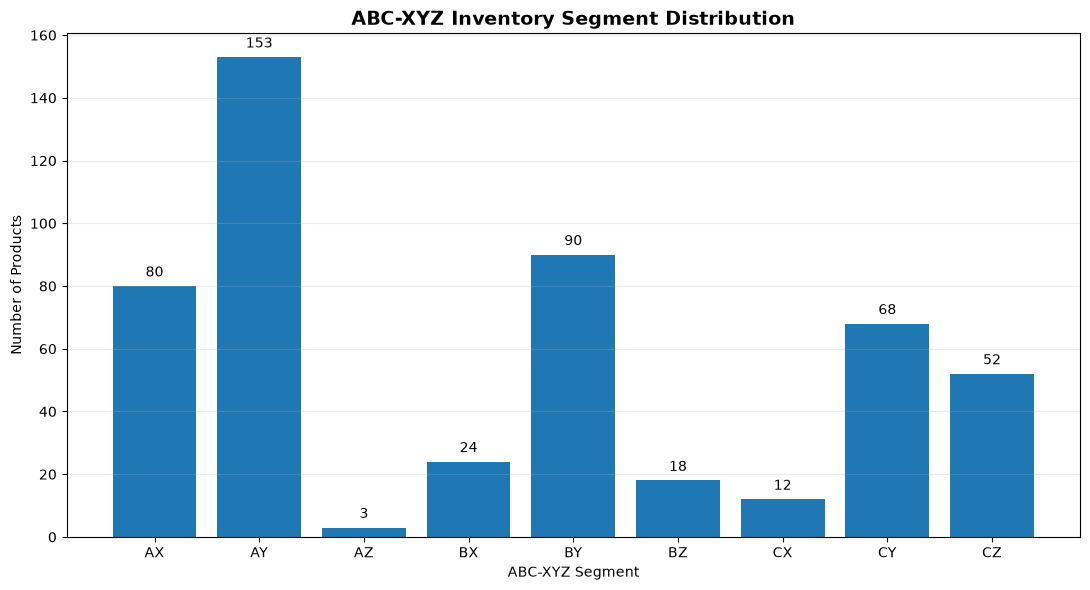

In [20]:
# ABC-XYZ Segment Distribution Visualization

segment_counts = (
    abc_xyz_analysis["abc_xyz_segment"]
    .value_counts()
    .reindex(segment_order)
)


plt.figure(figsize=(11, 6))

bars = plt.bar(
    segment_counts.index,
    segment_counts.values
)


plt.title(
    "ABC-XYZ Inventory Segment Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("ABC-XYZ Segment")
plt.ylabel("Number of Products")


# Add product count labels

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 2,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )


plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.show()

## Step 21 — Inventory Value by ABC–XYZ Segment

Visualize total inventory value across the nine ABC–XYZ segments.

This chart complements the product-count distribution by showing where inventory capital is concentrated.

It helps identify which segments require the greatest financial attention and inventory-control discipline.

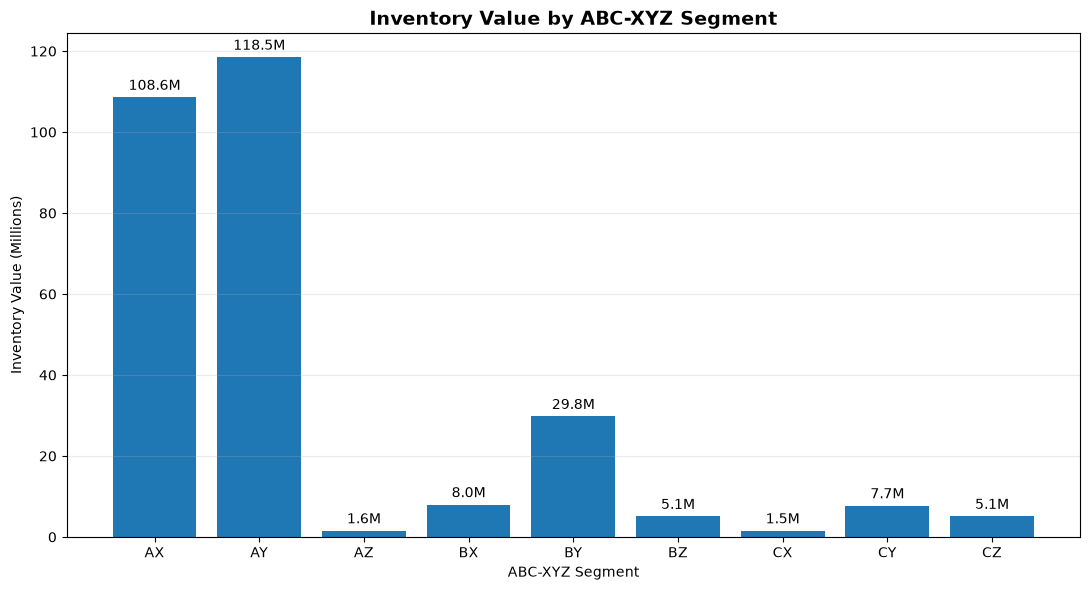

In [21]:
# Inventory Value by ABC-XYZ Segment

segment_inventory_value = (
    abc_xyz_analysis
    .groupby("abc_xyz_segment")[
        "total_inventory_value"
    ]
    .sum()
    .reindex(segment_order)
)


plt.figure(figsize=(11, 6))

bars = plt.bar(
    segment_inventory_value.index,
    segment_inventory_value.values / 1_000_000
)


plt.title(
    "Inventory Value by ABC-XYZ Segment",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("ABC-XYZ Segment")
plt.ylabel("Inventory Value (Millions)")


for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1,
        f"{height:.1f}M",
        ha="center",
        va="bottom"
    )


plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.show()

## Step 22 — ABC–XYZ Analysis Reconciliation

Perform reconciliation checks across the ABC–XYZ analysis.

The checks confirm that:

- ABC classifications cover all products
- XYZ classifications cover all products
- Combined ABC–XYZ segments cover all products
- ABC inventory value reconciles to the inventory dataset
- XYZ demand reconciles to historical SALE_ISSUE demand
- Product-count matrix reconciles
- Inventory-value matrix reconciles
- Demand matrix reconciles
- All products have an inventory-management strategy

These checks ensure analytical consistency before finalizing the notebook.

In [22]:
# ABC-XYZ Analysis Reconciliation

total_products = products["product_id"].nunique()

total_inventory_value = (
    product_inventory["total_inventory_value"].sum()
)

total_historical_demand = (
    complete_monthly_demand["monthly_demand"].sum()
)


reconciliation_checks = {

    "ABC Product Count":
        abc_summary["product_count"].sum()
        == total_products,

    "XYZ Product Count":
        xyz_summary["product_count"].sum()
        == total_products,

    "ABC-XYZ Product Count":
        abc_xyz_summary["product_count"].sum()
        == total_products,

    "ABC Inventory Value":
        np.isclose(
            abc_summary["inventory_value"].sum(),
            total_inventory_value
        ),

    "ABC-XYZ Inventory Value":
        np.isclose(
            abc_xyz_summary["inventory_value"].sum(),
            total_inventory_value
        ),

    "XYZ Historical Demand":
        np.isclose(
            xyz_summary["total_demand"].sum(),
            total_historical_demand
        ),

    "ABC-XYZ Historical Demand":
        np.isclose(
            abc_xyz_summary["total_demand"].sum(),
            total_historical_demand
        ),

    "Product Count Matrix":
        abc_xyz_matrix.loc["Total", "Total"]
        == total_products,

    "Inventory Value Matrix":
        np.isclose(
            inventory_value_matrix.loc["Total", "Total"],
            total_inventory_value
        ),

    "Demand Matrix":
        np.isclose(
            demand_matrix.loc["Total", "Total"],
            total_historical_demand
        ),

    "Complete Product-Month Matrix":
        len(complete_monthly_demand)
        == total_products * 33,

    "All Products Have Strategy":
        abc_xyz_analysis[
            "inventory_strategy"
        ].notna().all()
}


print("ABC-XYZ ANALYSIS RECONCILIATION\n")


for check, result in reconciliation_checks.items():

    print(
        f"{check:<38} : "
        f"{'PASS' if result else 'FAIL'}"
    )


abc_xyz_reconciliation_passed = all(
    reconciliation_checks.values()
)


print(
    "\nABC-XYZ ANALYSIS RECONCILIATION STATUS :",
    "PASSED"
    if abc_xyz_reconciliation_passed
    else "REVIEW REQUIRED"
)

ABC-XYZ ANALYSIS RECONCILIATION

ABC Product Count                      : PASS
XYZ Product Count                      : PASS
ABC-XYZ Product Count                  : PASS
ABC Inventory Value                    : PASS
ABC-XYZ Inventory Value                : PASS
XYZ Historical Demand                  : PASS
ABC-XYZ Historical Demand              : PASS
Product Count Matrix                   : PASS
Inventory Value Matrix                 : PASS
Demand Matrix                          : PASS
Complete Product-Month Matrix          : PASS
All Products Have Strategy             : PASS

ABC-XYZ ANALYSIS RECONCILIATION STATUS : PASSED


## Step 23 — Key Business Insights

### 1. ABC Inventory Concentration

The 500-product portfolio contains approximately **285.99 million** in inventory value.

ABC classification shows:

- **A Class:** 236 products (47.20%) hold **79.97%** of inventory value.
- **B Class:** 132 products (26.40%) hold **15.00%**.
- **C Class:** 132 products (26.40%) hold only **5.03%**.

Inventory capital is therefore strongly concentrated in A-class products, making them the primary focus for financial and inventory control.

---

### 2. Demand Predictability

XYZ classification based on 33 months of historical demand shows:

- **X:** 116 products (23.20%) generate **43.08%** of total demand.
- **Y:** 311 products (62.20%) generate **53.59%** of demand.
- **Z:** 73 products (14.60%) generate only **3.33%** of demand.

X products have relatively stable demand, while Z products exhibit substantial demand uncertainty and intermittency.

---

### 3. Intermittent Demand Risk

The 73 Z-class products account for **1,081 zero-demand product-months**.

Their relatively small **3.33% demand contribution** combined with high variability suggests that these products require conservative replenishment policies to avoid unnecessary inventory accumulation.

---

### 4. AX — Critical Stable-Demand Inventory

The **AX segment contains 80 products** representing:

- **108.62 million** in inventory value
- **37.98% of total inventory investment**
- **401,733 demand units**
- **31.89% of historical demand**

These products combine high financial importance with predictable demand.

AX products should receive the strongest service-level protection, accurate reorder-point management, frequent replenishment, and close stockout monitoring.

---

### 5. AY — Largest Inventory Exposure

The **AY segment contains 153 products** and represents approximately:

- **118.52 million** in inventory value
- **41.44% of total inventory investment**
- **373,412 demand units**
- **29.64% of historical demand**

AY is the largest segment by both product count and inventory value.

Because these products are financially important but have moderate demand variability, they require regular forecasting and dynamic safety-stock management.

---

### 6. AX + AY Dominate Inventory Investment

Together, AX and AY contain **233 products** but represent approximately:

- **227.14 million in inventory value**
- **79.42% of total inventory investment**
- **61.53% of historical demand**

Inventory-planning improvements focused on these two segments can therefore influence the majority of inventory capital.

---

### 7. AZ — High-Value Demand-Uncertainty Risk

Only **3 products** are classified as AZ.

They represent:

- Approximately **1.55 million** in inventory value
- **0.54% of inventory value**
- **2,828 demand units**
- **0.22% of historical demand**

Although total exposure is limited, each AZ product should be reviewed individually because these products combine A-class financial importance with Z-class demand uncertainty.

---

### 8. CZ — Low-Value Intermittent Inventory

The **CZ segment contains 52 products** representing:

- Approximately **5.12 million** in inventory value
- **1.79% of inventory investment**
- **26,471 demand units**
- **2.10% of historical demand**
- **822 zero-demand product-months**

Average CV for the segment is approximately **1.345**, confirming highly variable demand.

These products are strong candidates for leaner stocking, demand-driven replenishment, and inventory rationalization.

---

### 9. Category Exposure

**Electronics** represents the largest category with:

- **122 products**
- Approximately **79.18 million** in inventory value
- **335,327 historical demand units**

Electronics therefore deserves significant inventory-planning attention due to its high financial and demand exposure.

---

### 10. High-Value Unpredictable Products by Category

The three AZ products are concentrated in:

- **Home & Kitchen:** 2 products
- **Health & Personal Care:** 1 product

This allows the business to manage high-value unpredictable demand through targeted SKU-level review rather than a broad portfolio-wide intervention.

---

### 11. Segment-Specific Inventory Policies

The ABC–XYZ analysis demonstrates that a single inventory policy should not be applied across all 500 products.

Recommended management priorities include:

- **AX:** Tight control, high service levels, frequent replenishment
- **AY:** Close monitoring, forecasting, dynamic safety stock
- **AZ:** Frequent review and cautious stocking
- **BX/BY:** Standard or periodic replenishment with balanced safety stock
- **BZ:** Conservative demand-based replenishment
- **CX/CY:** Simplified and lower-intensity inventory control
- **CZ:** Minimal stock and demand-driven replenishment

---

## Management Takeaway

The portfolio's primary inventory-management priority should be the **AX and AY segments**, which together represent **79.42% of inventory value**.

AX products require strong availability protection because they combine high value with stable demand, while AY products require more active forecasting and safety-stock management because of their greater demand variability.

The **AZ segment is financially important but small enough for individual SKU management**, while the **CZ segment provides an opportunity to reduce unnecessary inventory investment in low-value, unpredictable products**.

ABC–XYZ segmentation therefore provides a practical framework for allocating inventory-management effort according to both **financial importance and demand predictability**.

## Step 24 — Final ABC–XYZ Analysis Validation

Perform the final validation of the ABC–XYZ Analysis notebook.

The validation confirms that:

- All 500 products are represented
- ABC classification is complete
- XYZ classification is complete
- All nine combined segments are valid
- Inventory value reconciles to the source inventory dataset
- Historical demand reconciles to SALE_ISSUE transactions
- The complete 33-month product-demand matrix is preserved
- ABC, XYZ, and combined classifications reconcile
- Product-count, inventory-value, and demand matrices reconcile
- Every product has an inventory-management strategy
- Step 22 reconciliation passed

This ensures that the ABC–XYZ segmentation is analytically consistent and ready for inventory optimization and dashboard reporting.

In [23]:
# Final ABC-XYZ Analysis Validation

valid_abc_classes = {"A", "B", "C"}
valid_xyz_classes = {"X", "Y", "Z"}

valid_abc_xyz_segments = {
    "AX", "AY", "AZ",
    "BX", "BY", "BZ",
    "CX", "CY", "CZ"
}


final_validation_checks = {

    "Product Count":
        len(abc_xyz_analysis) == 500,

    "Unique Product Count":
        abc_xyz_analysis["product_id"].nunique() == 500,

    "ABC Classification Complete":
        abc_xyz_analysis["abc_class"].notna().all(),

    "ABC Classes Valid":
        set(
            abc_xyz_analysis["abc_class"].astype(str).unique()
        ).issubset(valid_abc_classes),

    "XYZ Classification Complete":
        abc_xyz_analysis["xyz_class"].notna().all(),

    "XYZ Classes Valid":
        set(
            abc_xyz_analysis["xyz_class"].astype(str).unique()
        ).issubset(valid_xyz_classes),

    "ABC-XYZ Segments Complete":
        abc_xyz_analysis[
            "abc_xyz_segment"
        ].notna().all(),

    "ABC-XYZ Segments Valid":
        set(
            abc_xyz_analysis[
                "abc_xyz_segment"
            ].unique()
        ).issubset(valid_abc_xyz_segments),

    "Inventory Value Reconciles":
        np.isclose(
            abc_xyz_analysis[
                "total_inventory_value"
            ].sum(),
            285_985_182.04
        ),

    "Historical Demand Reconciles":
        np.isclose(
            abc_xyz_analysis[
                "total_demand"
            ].sum(),
            1_259_667
        ),

    "Product-Month Matrix Count":
        len(complete_monthly_demand)
        == 500 * 33,

    "Product-Month Demand Reconciles":
        np.isclose(
            complete_monthly_demand[
                "monthly_demand"
            ].sum(),
            1_259_667
        ),

    "ABC Summary Product Count":
        abc_summary[
            "product_count"
        ].sum() == 500,

    "XYZ Summary Product Count":
        xyz_summary[
            "product_count"
        ].sum() == 500,

    "Combined Summary Product Count":
        abc_xyz_summary[
            "product_count"
        ].sum() == 500,

    "Product Count Matrix Reconciles":
        abc_xyz_matrix.loc[
            "Total",
            "Total"
        ] == 500,

    "Inventory Value Matrix Reconciles":
        np.isclose(
            inventory_value_matrix.loc[
                "Total",
                "Total"
            ],
            285_985_182.04
        ),

    "Demand Matrix Reconciles":
        np.isclose(
            demand_matrix.loc[
                "Total",
                "Total"
            ],
            1_259_667
        ),

    "All Products Have Strategy":
        abc_xyz_analysis[
            "inventory_strategy"
        ].notna().all(),

    "Step 22 Reconciliation Passed":
        abc_xyz_reconciliation_passed
}


print("FINAL ABC-XYZ ANALYSIS VALIDATION\n")


for check, result in final_validation_checks.items():

    print(
        f"{check:<40} : "
        f"{'PASS' if result else 'FAIL'}"
    )


final_abc_xyz_status = all(
    final_validation_checks.values()
)


print(
    "\nFINAL ABC-XYZ ANALYSIS STATUS :",
    "PASSED"
    if final_abc_xyz_status
    else "REVIEW REQUIRED"
)

FINAL ABC-XYZ ANALYSIS VALIDATION

Product Count                            : PASS
Unique Product Count                     : PASS
ABC Classification Complete              : PASS
ABC Classes Valid                        : PASS
XYZ Classification Complete              : PASS
XYZ Classes Valid                        : PASS
ABC-XYZ Segments Complete                : PASS
ABC-XYZ Segments Valid                   : PASS
Inventory Value Reconciles               : PASS
Historical Demand Reconciles             : PASS
Product-Month Matrix Count               : PASS
Product-Month Demand Reconciles          : PASS
ABC Summary Product Count                : PASS
XYZ Summary Product Count                : PASS
Combined Summary Product Count           : PASS
Product Count Matrix Reconciles          : PASS
Inventory Value Matrix Reconciles        : PASS
Demand Matrix Reconciles                 : PASS
All Products Have Strategy               : PASS
Step 22 Reconciliation Passed            : PASS

FINA